# Luxury Cosmetics Fraud Analysis — 2025
**Python Data Analysis & Exploratory Data Analysis (EDA) Project**

## Objective
Explore transaction data to understand the distribution of transactions flagged for fraud, compare patterns across payment methods, devices, product categories and months, and communicate findings. `Fraud_Flag = 1` means the record is flagged in the source data; it is not independent confirmation of fraud.

**Workflow:** Select → Understand → Clean → Analyze → Visualize → Interpret → Conclude

## 1. Import libraries and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df_raw = pd.read_csv("luxury_cosmetics_fraud_analysis_2025.csv")
df = df_raw.copy()
df.head()

,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Time,Customer_Age,Customer_Loyalty_Tier,Location,Store_ID,Product_SKU,Product_Category,Purchase_Amount,Payment_Method,Device_Type,IP_Address,Fraud_Flag,Footfall_Count
0,702bdd9b-9c93-41e3-9dbb-a849b2422080,119dca0b-8554-4b2d-9bec-e964eaf6af97,2025-07-27,04:04:15,56.0,Silver,San Francisco,FLAGSHIP-LA,NEBULA-SERUM-07,Concealer,158.24,Mobile Payment,Desktop,239.249.58.237,0,333
1,2e64c346-36bc-4acf-bc2b-8b0fdf46abc5,299df086-26c4-4708-b6d7-fcaeceb14637,2025-03-14,20:23:23,46.0,Platinum,Zurich,BOUTIQUE-SHANGHAI,STELLAR-FOUND-03,Lipstick,86.03,Credit Card,Tablet,84.49.227.90,0,406
2,29ad1278-70ce-421f-8d81-23816b39f4ac,dfa3d24d-b935-49a5-aa1d-7d57a44d8773,2025-02-20,12:36:02,32.0,Silver,Milan,POPUP-TOKYO,SOLAR-BLUSH-04,Mascara,255.69,Gift Card,Desktop,79.207.35.55,0,96
3,07dc4894-e0eb-48f1-99a7-1942b1973d9b,7a67e184-9369-49ee-aeac-18f5b51b230f,2025-04-25,19:09:43,60.0,Bronze,London,BOUTIQUE-NYC,GALAXIA-SET-08,Serum,282.76,Gift Card,Mobile,176.194.167.253,0,186
4,ae407054-5543-429c-918a-cdcc42ea9782,cf14730a-8f5a-453d-b527-39a278852b27,2025-04-17,14:23:23,NaN,Platinum,Miami,BOUTIQUE-NYC,LUNAR-MASC-02,Serum,205.86,Gift Card,Mobile,166.31.46.111,0,179


## 2. Understand the dataset

In [2]:
print("Rows and columns:", df.shape)
print("\\nColumns:", df.columns.tolist())
df.info()
display(df.describe(include="all").T)
display(df.dtypes)

Rows and columns: (2133, 16)
\nColumns: ['Transaction_ID', 'Customer_ID', 'Transaction_Date', 'Transaction_Time', 'Customer_Age', 'Customer_Loyalty_Tier', 'Location', 'Store_ID', 'Product_SKU', 'Product_Category', 'Purchase_Amount', 'Payment_Method', 'Device_Type', 'IP_Address', 'Fraud_Flag', 'Footfall_Count']
<class 'pandas.DataFrame'>
RangeIndex: 2133 entries, 0 to 2132
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Transaction_ID         2133 non-null   str    
 1   Customer_ID            2133 non-null   str    
 2   Transaction_Date       2133 non-null   str    
 3   Transaction_Time       2133 non-null   str    
 4   Customer_Age           2027 non-null   float64
 5   Customer_Loyalty_Tier  2027 non-null   str    
 6   Location               2133 non-null   str    
 7   Store_ID               2133 non-null   str    
 8   Product_SKU            2133 non-null   str    
 9   Product_Categor

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Transaction_ID,2133,2133,702bdd9b-9c93-41e3-9dbb-a849b2422080,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_ID,2133,2133,119dca0b-8554-4b2d-9bec-e964eaf6af97,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transaction_Date,2133,180,2025-03-09,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transaction_Time,2133,2106,05:49:08,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Age,2027.0,NaN,NaN,NaN,41.684262,13.71811,18.0,30.0,42.0,53.0,65.0
Customer_Loyalty_Tier,2027,5,Bronze,808,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,2133,20,Sydney,128,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_ID,2133,10,FLAGSHIP-PARIS,234,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_SKU,2133,10,ECLIPSE-EYE-10,235,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Category,2133,10,Serum,233,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Transaction_ID               str
Customer_ID                  str
Transaction_Date             str
Transaction_Time             str
Customer_Age             float64
Customer_Loyalty_Tier        str
Location                     str
Store_ID                     str
Product_SKU                  str
Product_Category             str
Purchase_Amount          float64
Payment_Method               str
Device_Type                  str
IP_Address                   str
Fraud_Flag                 int64
Footfall_Count             int64
dtype: object

Each row represents a transaction record. The data contains transaction/customer identifiers, date/time, customer attributes, location/store/product, payment/device, a fraud flag and footfall count.

## 3. Initial data-quality inspection

In [3]:
print("Missing values per column:")
display(df.isnull().sum().sort_values(ascending=False))
print("Exact duplicate rows:", df.duplicated().sum())
print("Unique values per column:")
display(df.nunique().sort_values())

Missing values per column:


Customer_Loyalty_Tier    106
Customer_Age             106
Payment_Method           106
Transaction_ID             0
Transaction_Time           0
Transaction_Date           0
Location                   0
Customer_ID                0
Store_ID                   0
Product_SKU                0
Product_Category           0
Purchase_Amount            0
Device_Type                0
IP_Address                 0
Fraud_Flag                 0
Footfall_Count             0
dtype: int64

Exact duplicate rows: 0
Unique values per column:


Fraud_Flag                  2
Payment_Method              4
Device_Type                 4
Customer_Loyalty_Tier       5
Product_SKU                10
Store_ID                   10
Product_Category           10
Location                   20
Customer_Age               48
Transaction_Date          180
Footfall_Count            446
Purchase_Amount          2058
Transaction_Time         2106
Transaction_ID           2133
Customer_ID              2133
IP_Address               2133
dtype: int64

### Cleaning decisions
- Convert transaction date/time to appropriate types.
- Convert numeric fields safely.
- There are 106 missing values each in `Customer_Age`, `Customer_Loyalty_Tier`, and `Payment_Method`.
- Impute missing customer ages with the median because age is numeric and the median is less sensitive to extreme values.
- Label missing loyalty/payment values as `Unknown` rather than inventing a category.
- No exact full-row duplicates were found, so no rows are removed on duplicate grounds.
- Keep the raw dataframe unchanged so results can be compared with the cleaned version.

In [4]:
df["Transaction_Date"] = pd.to_datetime(df["Transaction_Date"], errors="coerce")
df["Transaction_Time"] = pd.to_datetime(
    df["Transaction_Time"], format="%H:%M:%S", errors="coerce"
).dt.time
for col in ["Customer_Age", "Purchase_Amount", "Footfall_Count", "Fraud_Flag"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["Customer_Age"] = df["Customer_Age"].fillna(df["Customer_Age"].median())
for col in ["Customer_Loyalty_Tier", "Payment_Method"]:
    df[col] = df[col].fillna("Unknown")

df["YearMonth"] = df["Transaction_Date"].dt.to_period("M").astype(str)
df["Hour"] = pd.to_datetime(df["Transaction_Time"].astype(str), format="%H:%M:%S", errors="coerce").dt.hour
print("Remaining missing values:")
display(df.isna().sum())
df.head()

Remaining missing values:


Transaction_ID           0
Customer_ID              0
Transaction_Date         0
Transaction_Time         0
Customer_Age             0
Customer_Loyalty_Tier    0
Location                 0
Store_ID                 0
Product_SKU              0
Product_Category         0
Purchase_Amount          0
Payment_Method           0
Device_Type              0
IP_Address               0
Fraud_Flag               0
Footfall_Count           0
YearMonth                0
Hour                     0
dtype: int64

,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Time,Customer_Age,Customer_Loyalty_Tier,Location,Store_ID,Product_SKU,Product_Category,Purchase_Amount,Payment_Method,Device_Type,IP_Address,Fraud_Flag,Footfall_Count,YearMonth,Hour
0,702bdd9b-9c93-41e3-9dbb-a849b2422080,119dca0b-8554-4b2d-9bec-e964eaf6af97,2025-07-27,04:04:15,56.0,Silver,San Francisco,FLAGSHIP-LA,NEBULA-SERUM-07,Concealer,158.24,Mobile Payment,Desktop,239.249.58.237,0,333,2025-07,4
1,2e64c346-36bc-4acf-bc2b-8b0fdf46abc5,299df086-26c4-4708-b6d7-fcaeceb14637,2025-03-14,20:23:23,46.0,Platinum,Zurich,BOUTIQUE-SHANGHAI,STELLAR-FOUND-03,Lipstick,86.03,Credit Card,Tablet,84.49.227.90,0,406,2025-03,20
2,29ad1278-70ce-421f-8d81-23816b39f4ac,dfa3d24d-b935-49a5-aa1d-7d57a44d8773,2025-02-20,12:36:02,32.0,Silver,Milan,POPUP-TOKYO,SOLAR-BLUSH-04,Mascara,255.69,Gift Card,Desktop,79.207.35.55,0,96,2025-02,12
3,07dc4894-e0eb-48f1-99a7-1942b1973d9b,7a67e184-9369-49ee-aeac-18f5b51b230f,2025-04-25,19:09:43,60.0,Bronze,London,BOUTIQUE-NYC,GALAXIA-SET-08,Serum,282.76,Gift Card,Mobile,176.194.167.253,0,186,2025-04,19
4,ae407054-5543-429c-918a-cdcc42ea9782,cf14730a-8f5a-453d-b527-39a278852b27,2025-04-17,14:23:23,42.0,Platinum,Miami,BOUTIQUE-NYC,LUNAR-MASC-02,Serum,205.86,Gift Card,Mobile,166.31.46.111,0,179,2025-04,14


## 4. Basic statistical analysis

In [5]:
print("Total transactions:", len(df))
print("Total purchase amount:", round(df["Purchase_Amount"].sum(), 2))
print("Average purchase amount:", round(df["Purchase_Amount"].mean(), 2))
print("Median purchase amount:", round(df["Purchase_Amount"].median(), 2))
print("Flagged transactions:", int(df["Fraud_Flag"].sum()))
print("Flagged transaction rate (%):", round(df["Fraud_Flag"].mean() * 100, 2))
display(df[["Customer_Age", "Purchase_Amount", "Footfall_Count"]].describe())

Total transactions: 2133
Total purchase amount: 372451.82
Average purchase amount: 174.61
Median purchase amount: 174.18
Flagged transactions: 66
Flagged transaction rate (%): 3.09


,Customer_Age,Purchase_Amount,Footfall_Count
count,2133.000000,2133.000000,2133.000000
mean,41.699953,174.614074,272.461791
std,13.372916,72.249043,131.113027
min,18.000000,50.260000,50.000000
25%,30.000000,113.850000,157.000000
50%,42.000000,174.180000,269.000000
75%,53.000000,236.360000,388.000000
max,65.000000,299.910000,500.000000


## 5. Univariate analysis

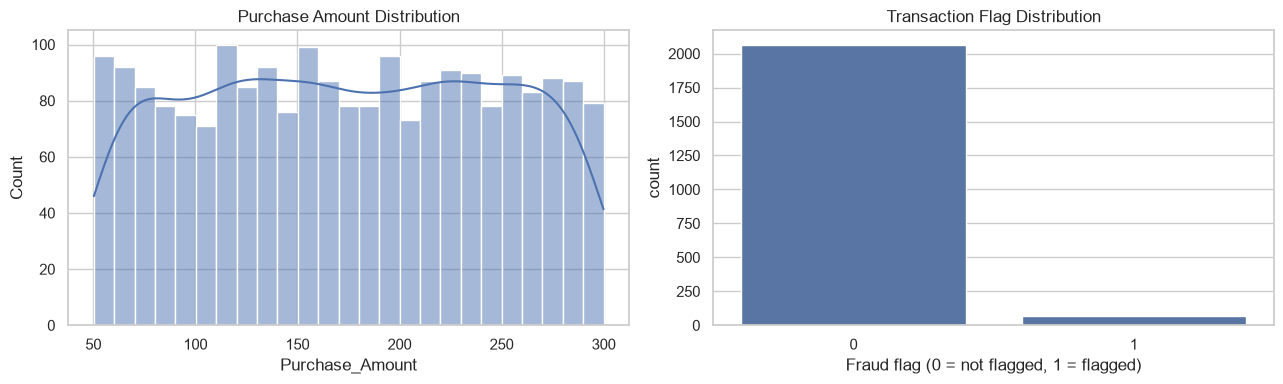

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["Purchase_Amount"], bins=25, kde=True, ax=axes[0])
axes[0].set_title("Purchase Amount Distribution")
sns.countplot(data=df, x="Fraud_Flag", ax=axes[1])
axes[1].set_title("Transaction Flag Distribution")
axes[1].set_xlabel("Fraud flag (0 = not flagged, 1 = flagged)")
plt.tight_layout()
plt.show()

## 6. Bivariate analysis

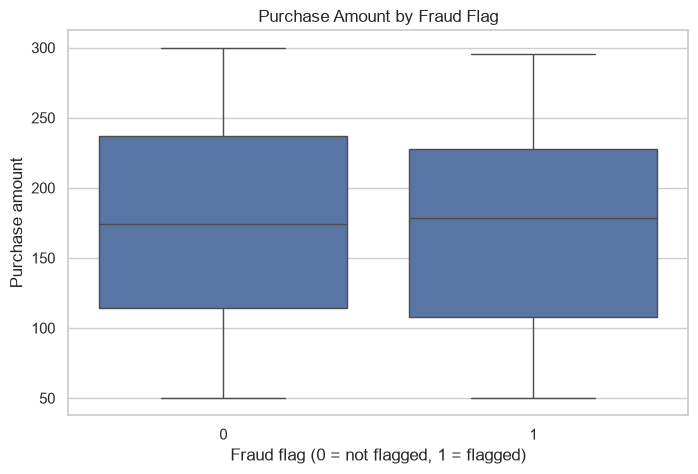

,transactions,flagged,flagged_rate,purchase_total
Payment_Method,,,,
Unknown,106,4,0.037736,19174.61
Debit Card,522,17,0.032567,93307.32
Gift Card,514,16,0.031128,89200.47
Mobile Payment,500,15,0.030000,87053.00
Credit Card,491,14,0.028513,83716.42


In [7]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Fraud_Flag", y="Purchase_Amount")
plt.title("Purchase Amount by Fraud Flag")
plt.xlabel("Fraud flag (0 = not flagged, 1 = flagged)")
plt.ylabel("Purchase amount")
plt.show()

payment_summary = df.groupby("Payment_Method").agg(
    transactions=("Transaction_ID", "count"),
    flagged=("Fraud_Flag", "sum"),
    flagged_rate=("Fraud_Flag", "mean"),
    purchase_total=("Purchase_Amount", "sum")
).sort_values("flagged_rate", ascending=False)
display(payment_summary)

## 7. Time trend and grouping

,YearMonth,transactions,flagged,flagged_rate,purchase_total
0,2025-02,157,5,0.031847,26589.36
1,2025-03,373,12,0.032172,63560.44
2,2025-04,348,6,0.017241,61825.58
3,2025-05,357,9,0.025210,63637.15
4,2025-06,358,11,0.030726,59736.94
5,2025-07,378,15,0.039683,67644.08
6,2025-08,162,8,0.049383,29458.27


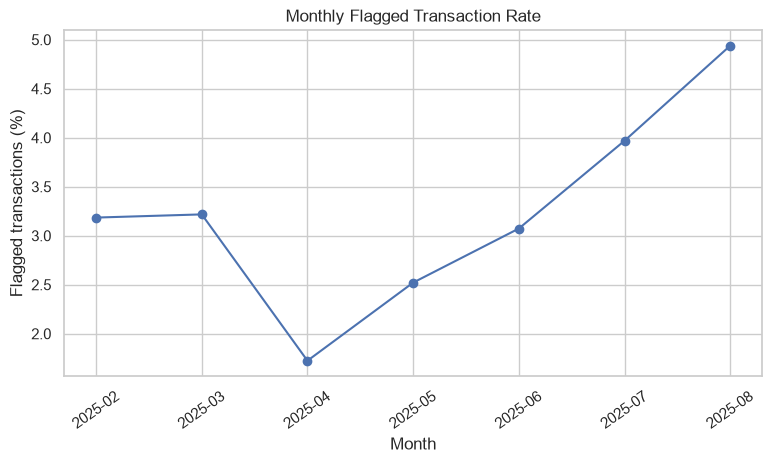

,transactions,purchase_total,flagged_rate
Product_Category,,,
Serum,233,39897.57,0.021459
Setting Spray,213,38664.84,0.046948
Highlighter,228,37671.00,0.008772
Concealer,199,37566.80,0.025126
Blush,222,37546.53,0.040541
Mascara,219,37193.03,0.041096
Eyeshadow Palette,209,36416.71,0.028708
Eyeliner,207,35943.26,0.028986
Foundation,194,35783.67,0.020619


In [8]:
monthly = df.groupby("YearMonth").agg(
    transactions=("Transaction_ID", "count"),
    flagged=("Fraud_Flag", "sum"),
    flagged_rate=("Fraud_Flag", "mean"),
    purchase_total=("Purchase_Amount", "sum")
).reset_index()
display(monthly)

plt.figure(figsize=(9, 4.5))
plt.plot(monthly["YearMonth"], monthly["flagged_rate"] * 100, marker="o")
plt.title("Monthly Flagged Transaction Rate")
plt.xlabel("Month")
plt.ylabel("Flagged transactions (%)")
plt.xticks(rotation=35)
plt.show()

category_summary = df.groupby("Product_Category").agg(
    transactions=("Transaction_ID", "count"),
    purchase_total=("Purchase_Amount", "sum"),
    flagged_rate=("Fraud_Flag", "mean")
).sort_values("purchase_total", ascending=False)
display(category_summary)

## 8. Sorting, filtering, loc, iloc and replace

In [9]:
# Filtering
high_value = df[df["Purchase_Amount"] > 250]
display(high_value.head())

# Conditional selection
filtered = df[(df["Fraud_Flag"] == 1) & (df["Purchase_Amount"] > 200)]
display(filtered.head())

# loc and iloc
display(df.loc[df["Purchase_Amount"] > 250, ["Transaction_ID", "Purchase_Amount", "Fraud_Flag"]].head())
display(df.iloc[0:10])

# Sorting / ranking
display(df.sort_values("Purchase_Amount", ascending=False).head(5))

# Replace: demonstrate standardization on a copy only (no assumed mapping needed in this dataset)
example = df["Customer_Loyalty_Tier"].replace({"VIP": "VIP"})
display(example.value_counts(dropna=False))

,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Time,Customer_Age,Customer_Loyalty_Tier,Location,Store_ID,Product_SKU,Product_Category,Purchase_Amount,Payment_Method,Device_Type,IP_Address,Fraud_Flag,Footfall_Count,YearMonth,Hour
2,29ad1278-70ce-421f-8d81-23816b39f4ac,dfa3d24d-b935-49a5-aa1d-7d57a44d8773,2025-02-20,12:36:02,32.0,Silver,Milan,POPUP-TOKYO,SOLAR-BLUSH-04,Mascara,255.69,Gift Card,Desktop,79.207.35.55,0,96,2025-02,12
3,07dc4894-e0eb-48f1-99a7-1942b1973d9b,7a67e184-9369-49ee-aeac-18f5b51b230f,2025-04-25,19:09:43,60.0,Bronze,London,BOUTIQUE-NYC,GALAXIA-SET-08,Serum,282.76,Gift Card,Mobile,176.194.167.253,0,186,2025-04,19
10,fc5f93c2-a371-4c78-a3eb-ab6c046f0466,fcf9043c-2546-40ae-b048-ab272dc47322,2025-03-08,05:31:33,28.0,Gold,Dubai,CONCESSION-SINGAPORE,GALAXIA-SET-08,Serum,286.26,Mobile Payment,Laptop,150.4.206.65,0,77,2025-03,5
15,42cb6225-c75b-44cd-8808-031672803880,95ebedcd-f361-4e04-9547-fb1c104df1eb,2025-03-09,22:58:31,20.0,VIP,Milan,CONCESSION-LONDON,SOLAR-BLUSH-04,Serum,270.14,Unknown,Laptop,104.195.222.108,0,65,2025-03,22
28,3ab90b8b-761e-49dd-89ac-6ab38bc12af8,97d35805-42ea-43ba-8aa3-819e18558dcb,2025-06-08,15:01:23,42.0,Unknown,Dubai,BOUTIQUE-NYC,LUNAR-MASC-02,Foundation,285.54,Mobile Payment,Laptop,29.246.40.72,0,266,2025-06,15


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Time,Customer_Age,Customer_Loyalty_Tier,Location,Store_ID,Product_SKU,Product_Category,Purchase_Amount,Payment_Method,Device_Type,IP_Address,Fraud_Flag,Footfall_Count,YearMonth,Hour
61,b42012a5-4d94-43d7-ac05-ab83c836c7ed,b0424357-77dc-444d-a341-9e5e4e54309d,2025-03-03,18:26:39,21.0,VIP,Miami,CONCESSION-LONDON,COSMIC-HIGHLIGHT-06,Blush,200.35,Unknown,Mobile,176.228.179.112,1,256,2025-03,18
291,67232ffe-b1e9-43ba-bb7c-05efdc870d75,448a6b76-d4c2-488d-885b-db63593bd0e2,2025-05-29,09:24:11,37.0,Gold,Cannes,CONCESSION-LONDON,LUNAR-MASC-02,Mascara,295.23,Mobile Payment,Desktop,68.253.193.180,1,472,2025-05,9
336,78f390a1-8847-4b34-8523-ed9384d183f8,7a78a536-bb08-4b83-9b63-6301ae2e7ef5,2025-07-09,23:31:29,50.0,Silver,London,FLAGSHIP-ROME,COSMIC-HIGHLIGHT-06,Lipstick,272.19,Unknown,Desktop,37.54.89.109,1,399,2025-07,23
397,884cc8ec-3608-4e80-adbe-4201f43fe64f,8d2ef1b8-1b66-48f2-a6d4-bf6a96ddc1ed,2025-03-25,10:38:49,37.0,Platinum,Shanghai,FLAGSHIP-LA,STELLAR-FOUND-03,Lipstick,249.16,Debit Card,Tablet,255.253.20.226,1,60,2025-03,10
531,5638ef68-6be9-487e-a290-81a941449ed4,45304992-d6e7-422c-a7a9-0345d10c9e67,2025-06-23,04:12:52,40.0,Silver,Dubai,FLAGSHIP-PARIS,ECLIPSE-EYE-10,Lipstick,230.42,Mobile Payment,Laptop,210.250.1.62,1,385,2025-06,4


,Transaction_ID,Purchase_Amount,Fraud_Flag
2,29ad1278-70ce-421f-8d81-23816b39f4ac,255.69,0
3,07dc4894-e0eb-48f1-99a7-1942b1973d9b,282.76,0
10,fc5f93c2-a371-4c78-a3eb-ab6c046f0466,286.26,0
15,42cb6225-c75b-44cd-8808-031672803880,270.14,0
28,3ab90b8b-761e-49dd-89ac-6ab38bc12af8,285.54,0


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Time,Customer_Age,Customer_Loyalty_Tier,Location,Store_ID,Product_SKU,Product_Category,Purchase_Amount,Payment_Method,Device_Type,IP_Address,Fraud_Flag,Footfall_Count,YearMonth,Hour
0,702bdd9b-9c93-41e3-9dbb-a849b2422080,119dca0b-8554-4b2d-9bec-e964eaf6af97,2025-07-27,04:04:15,56.0,Silver,San Francisco,FLAGSHIP-LA,NEBULA-SERUM-07,Concealer,158.24,Mobile Payment,Desktop,239.249.58.237,0,333,2025-07,4
1,2e64c346-36bc-4acf-bc2b-8b0fdf46abc5,299df086-26c4-4708-b6d7-fcaeceb14637,2025-03-14,20:23:23,46.0,Platinum,Zurich,BOUTIQUE-SHANGHAI,STELLAR-FOUND-03,Lipstick,86.03,Credit Card,Tablet,84.49.227.90,0,406,2025-03,20
2,29ad1278-70ce-421f-8d81-23816b39f4ac,dfa3d24d-b935-49a5-aa1d-7d57a44d8773,2025-02-20,12:36:02,32.0,Silver,Milan,POPUP-TOKYO,SOLAR-BLUSH-04,Mascara,255.69,Gift Card,Desktop,79.207.35.55,0,96,2025-02,12
3,07dc4894-e0eb-48f1-99a7-1942b1973d9b,7a67e184-9369-49ee-aeac-18f5b51b230f,2025-04-25,19:09:43,60.0,Bronze,London,BOUTIQUE-NYC,GALAXIA-SET-08,Serum,282.76,Gift Card,Mobile,176.194.167.253,0,186,2025-04,19
4,ae407054-5543-429c-918a-cdcc42ea9782,cf14730a-8f5a-453d-b527-39a278852b27,2025-04-17,14:23:23,42.0,Platinum,Miami,BOUTIQUE-NYC,LUNAR-MASC-02,Serum,205.86,Gift Card,Mobile,166.31.46.111,0,179,2025-04,14
5,43a8a133-69a0-4d20-bf2a-d6d2b83e0d3d,f0b34554-3841-45b1-a27e-62c347855e7d,2025-04-12,14:48:04,38.0,Gold,Sydney,POPUP-TOKYO,SOLAR-BLUSH-04,Eyeliner,135.91,Mobile Payment,Tablet,210.71.0.75,0,244,2025-04,14
6,51175e91-b199-4b3e-9810-99b533492d2e,2d3c1dd3-6844-44f0-ae89-42e7b147b31d,2025-03-21,18:08:33,56.0,Gold,Sydney,FLAGSHIP-ROME,STELLAR-FOUND-03,Serum,88.50,Gift Card,Mobile,170.76.231.149,0,166,2025-03,18
7,9b5f7324-c8b2-4e36-a888-b0a3aeefd071,7f8cf7cb-a367-4120-8be5-dcefd452262c,2025-03-12,11:25:20,36.0,Bronze,Shanghai,BOUTIQUE-DUBAI,ORION-CONCEAL-09,Eyeliner,116.29,Mobile Payment,Mobile,100.228.100.105,0,413,2025-03,11
8,d1563d4b-de86-47c5-9df6-bc78259834a8,8d7bd046-4a87-4c8c-850e-4d55f4767119,2025-08-06,20:17:15,40.0,Gold,Shanghai,POPUP-TOKYO,ECLIPSE-EYE-10,Serum,113.85,Credit Card,Tablet,175.162.153.155,0,481,2025-08,20
9,2ee80052-067d-4ff2-87a6-ec8919d13546,3ae3b36f-25bb-48ca-afee-7c524b58e1a0,2025-07-03,03:01:47,28.0,Bronze,Tokyo,BOUTIQUE-SHANGHAI,ORION-CONCEAL-09,Mascara,203.38,Credit Card,Desktop,236.222.176.45,0,118,2025-07,3


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Time,Customer_Age,Customer_Loyalty_Tier,Location,Store_ID,Product_SKU,Product_Category,Purchase_Amount,Payment_Method,Device_Type,IP_Address,Fraud_Flag,Footfall_Count,YearMonth,Hour
332,fdfb3d60-69c7-4216-8ce5-6cee9068987a,18fe1a22-6405-4333-8de2-155667080a35,2025-08-05,07:31:35,47.0,Silver,Geneva,POPUP-TOKYO,SOLAR-BLUSH-04,Setting Spray,299.91,Mobile Payment,Tablet,61.57.61.128,0,89,2025-08,7
434,1efd0bf4-3c4a-44df-969d-b82201cf6966,3f160312-fdba-4b34-aea9-e88855c986bd,2025-07-13,14:06:08,33.0,Silver,Rome,FLAGSHIP-LA,AURORA-LIP-01,Foundation,299.83,Mobile Payment,Tablet,190.236.91.93,0,52,2025-07,14
1395,0d62bd20-878a-47be-a91b-f0f02b5d3440,35c2cfa0-e200-4cad-a241-351112185195,2025-07-21,23:07:30,62.0,Gold,Miami,POPUP-MILAN,SOLAR-BLUSH-04,Highlighter,299.77,Gift Card,Tablet,50.175.223.29,0,211,2025-07,23
772,2c5d4d89-fc0e-4c97-b956-3ec80cd3cb3e,3c945570-5c05-4bdc-8cd9-efdc73402455,2025-08-11,00:24:43,31.0,Bronze,Las Vegas,FLAGSHIP-ROME,STELLAR-FOUND-03,Eyeshadow Palette,299.49,Unknown,Tablet,148.229.103.139,0,103,2025-08,0
1063,b4b08adf-75fa-45b8-8d55-74a8edcea540,7b8ad07b-bb99-48d9-bc5d-6ab19914c8ab,2025-03-08,12:56:40,43.0,Silver,Las Vegas,POPUP-MILAN,ORION-CONCEAL-09,Highlighter,299.39,Debit Card,Laptop,97.13.217.190,0,133,2025-03,12


Customer_Loyalty_Tier
Bronze      808
Silver      506
Gold        423
Platinum    179
VIP         111
Unknown     106
Name: count, dtype: int64

## 9. Pivot table and crosstab

In [10]:
pivot = pd.pivot_table(
    df, values="Purchase_Amount", index="Location",
    columns="Product_Category", aggfunc="sum", fill_value=0
)
display(pivot.head(10))

cross = pd.crosstab(df["Payment_Method"], df["Fraud_Flag"], margins=True)
display(cross)

Product_Category,Blush,Concealer,Eyeliner,Eyeshadow Palette,Foundation,Highlighter,Lipstick,Mascara,Serum,Setting Spray
Location,,,,,,,,,,
Cannes,3132.50,1312.08,1774.83,2389.73,1219.04,2689.80,2202.23,2439.65,1654.66,1011.02
Dubai,1815.24,1516.88,775.50,1331.35,1606.59,2137.01,1445.67,3064.74,1573.92,2696.00
Geneva,2124.08,1558.33,2456.19,1437.34,1365.06,1287.67,1405.76,1621.44,2006.34,1940.03
Hong Kong,1567.08,2245.81,1625.22,2748.72,2007.99,2057.39,2225.25,1965.58,2246.32,2121.98
Las Vegas,1638.19,2342.68,1473.11,1917.08,2287.51,1270.47,1608.54,1336.96,1739.31,1636.43
London,1632.86,2057.81,2932.98,1718.39,2296.99,2058.21,1016.93,1538.48,1244.15,2168.63
Los Angeles,1399.74,1082.53,1191.15,1359.47,1889.31,2212.19,1927.92,1747.28,2588.31,2485.09
Miami,1899.34,1054.39,2229.54,1290.19,542.54,1898.55,2832.10,1741.18,2019.82,3081.61
Milan,1371.30,1681.25,1782.39,1808.40,1333.70,1784.65,1986.14,1670.18,1664.23,2664.92


Fraud_Flag,0,1,All
Payment_Method,,,
Credit Card,477,14,491
Debit Card,505,17,522
Gift Card,498,16,514
Mobile Payment,485,15,500
Unknown,102,4,106
All,2067,66,2133


## 10. NumPy and correlation

NumPy mean: 174.61407407407407
NumPy median: 174.18
NumPy standard deviation: 72.23210470208886
Minimum / maximum: 50.26 299.91
Top five purchase amounts: [299.39 299.49 299.77 299.83 299.91]


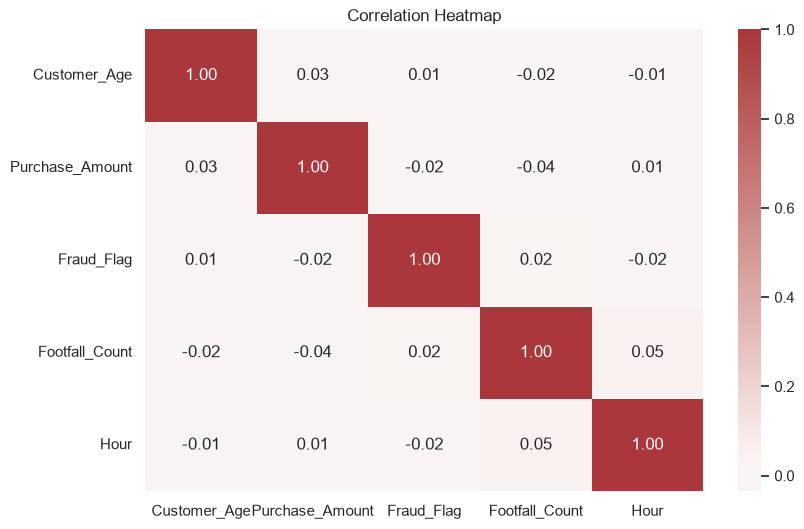

In [11]:
amounts = df["Purchase_Amount"].to_numpy()
print("NumPy mean:", np.mean(amounts))
print("NumPy median:", np.median(amounts))
print("NumPy standard deviation:", np.std(amounts))
print("Minimum / maximum:", np.min(amounts), np.max(amounts))
print("Top five purchase amounts:", np.sort(amounts)[-5:])

numeric = df.select_dtypes(include=np.number)
corr = numeric.corr()
plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlation Heatmap")
plt.show()

## 11. Extra advanced graph: Payment × Device risk matrix
This heatmap compares the percentage of records flagged within each payment-method/device-type combination. Treat small groups cautiously: a high percentage from few transactions may be unstable, and a flagged rate is not proof of confirmed fraud.

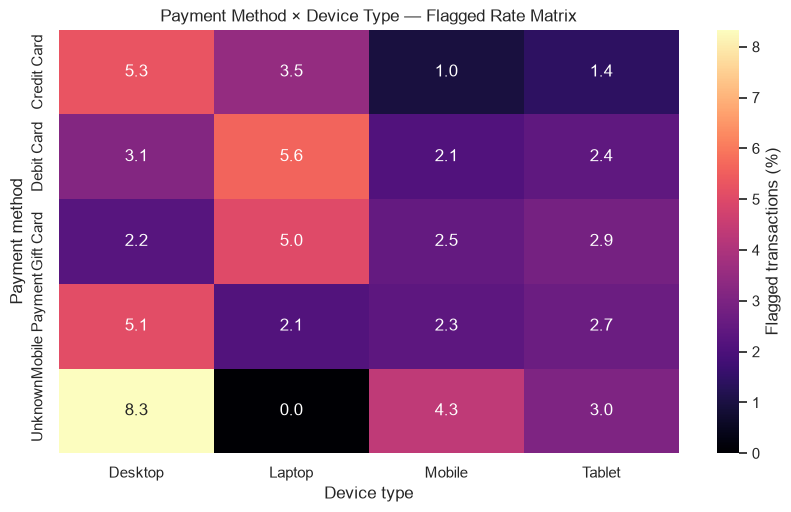

In [12]:
risk_matrix = pd.pivot_table(
    df, index="Payment_Method", columns="Device_Type",
    values="Fraud_Flag", aggfunc="mean"
)
plt.figure(figsize=(10, 5.5))
sns.heatmap(risk_matrix * 100, annot=True, fmt=".1f", cmap="magma",
            cbar_kws={"label": "Flagged transactions (%)"})
plt.title("Payment Method × Device Type — Flagged Rate Matrix")
plt.xlabel("Device type")
plt.ylabel("Payment method")
plt.show()

## 12. Key findings and conclusion

- The dataset contains **2,133 transactions** across **16 columns**.
- **66 transactions (3.09%)** have `Fraud_Flag = 1`.
- Total recorded purchase amount is **372,451.82**, with an average of **174.61** per transaction.
- The month with the highest observed flagged rate is **2025-08** at **4.94%**; monthly counts vary, so compare both rate and volume.
- The largest product-category purchase total is **Serum** at **39,897.57**.
- Missing age, loyalty-tier and payment-method values should be treated transparently; missing categorical values are retained as `Unknown`.
- Use payment/device combinations as investigation leads, not as automatic evidence of wrongdoing.

**Conclusion:** The EDA describes transaction patterns and identifies segments for further review. This dataset alone does not establish why a transaction was flagged, and correlation does not prove causation. Validate unusual patterns with business rules and confirmed case outcomes before making operational decisions.